# Практическое задание 1: Exploratory Data Analysis

В этом задании вам предстоит предстоит произвести анализ и преобразование твиттов TopG Трампа

In [210]:
from IPython.display import clear_output
!pip install nltk
!pip install wordcloud
!pip install scikit-learn
clear_output()

In [211]:
import numpy as np
import pandas as pd
from typing import  List
import matplotlib.pyplot as plt
import seaborn as sns
from string import punctuation
import nltk
import wordcloud

In [212]:
df = pd.read_json('trump_truths_dataset.json')
df.head()

,account_name,account_handle,verified_badge,post_date,profile_link,avatar_url,post_url,status_text,video_urls,replies,shares,likes,image_urls
0,Donald J. Trump,realDonaldTrump,True,2024-11-08 10:05:00,https://truthsocial.com/@realDonaldTrump,https://static-assets-1.truthsocial.com/tmtg:p...,https://truthsocial.com/@realDonaldTrump/posts...,"There are fake, untrue, and probably illegal r...",None,429,"1,41k","5,01k",None
1,Donald J. Trump,realDonaldTrump,True,2024-11-07 21:56:00,https://truthsocial.com/@realDonaldTrump,https://static-assets-1.truthsocial.com/tmtg:p...,https://truthsocial.com/@realDonaldTrump/posts...,,None,"4,29k","9,58k","46,2k",[https://static-assets-1.truthsocial.com/tmtg:...
2,Donald J. Trump,realDonaldTrump,True,2024-11-07 21:56:00,https://truthsocial.com/@realDonaldTrump,https://static-assets-1.truthsocial.com/tmtg:p...,https://truthsocial.com/@realDonaldTrump/posts...,,None,"1,11k","6,64k","32,2k",[https://static-assets-1.truthsocial.com/tmtg:...
3,Donald J. Trump,realDonaldTrump,True,2024-11-07 21:56:00,https://truthsocial.com/@realDonaldTrump,https://static-assets-1.truthsocial.com/tmtg:p...,https://truthsocial.com/@realDonaldTrump/posts...,,None,"2,85k","13,3k","63,5k",[https://static-assets-1.truthsocial.com/tmtg:...
4,Donald J. Trump,realDonaldTrump,True,2024-11-07 21:55:00,https://truthsocial.com/@realDonaldTrump,https://static-assets-1.truthsocial.com/tmtg:p...,https://truthsocial.com/@realDonaldTrump/posts...,,None,623,"4,31k","21,8k",[https://static-assets-1.truthsocial.com/tmtg:...


In [213]:
df.columns

Index(['account_name', 'account_handle', 'verified_badge', 'post_date',
       'profile_link', 'avatar_url', 'post_url', 'status_text', 'video_urls',
       'replies', 'shares', 'likes', 'image_urls'],
      dtype='str')

Для каждого поста указано:

* account_name — имя аккаунта пользователя (например, "Donald J. Trump")
* account_handle — уникальный логин пользователя (например, "@realDonaldTrump")
* verified_badge — наличие верификации аккаунта
* post_date — дата и время публикации поста
* profile_link — ссылка на профиль пользователя в социальной сети
* avatar_url — ссылка на аватар пользователя
* post_url — ссылка на сам пост
* status_text — текст публикации (основное содержание, текстовый пост)
* video_urls - ссылка на видео
* replies — количество ответов на пост
* shares — количество репостов или делений постом
* likes — количество лайков поста
* image_urls - ссылки на картинки/видео


In [214]:
len(df)

5159

## Задание 1 Подготовка (1 балл)

Иногда для знакомства с датасетом бывает полезно взглянуть на облако слов. Для этого можно использовать библиотеку `wordcloud`. Выведите облако слов для текста пост

In [215]:
from wordcloud import WordCloud

def create_cloud_graph(corpus):
    wordcloud = WordCloud(
        width=1600, height=800, max_words=200, background_color='white', collocations=False
    ).generate(' '.join(corpus))
    plt.figure(figsize=(20,10))
    plt.imshow(wordcloud)
    plt.axis("off")
    plt.show()

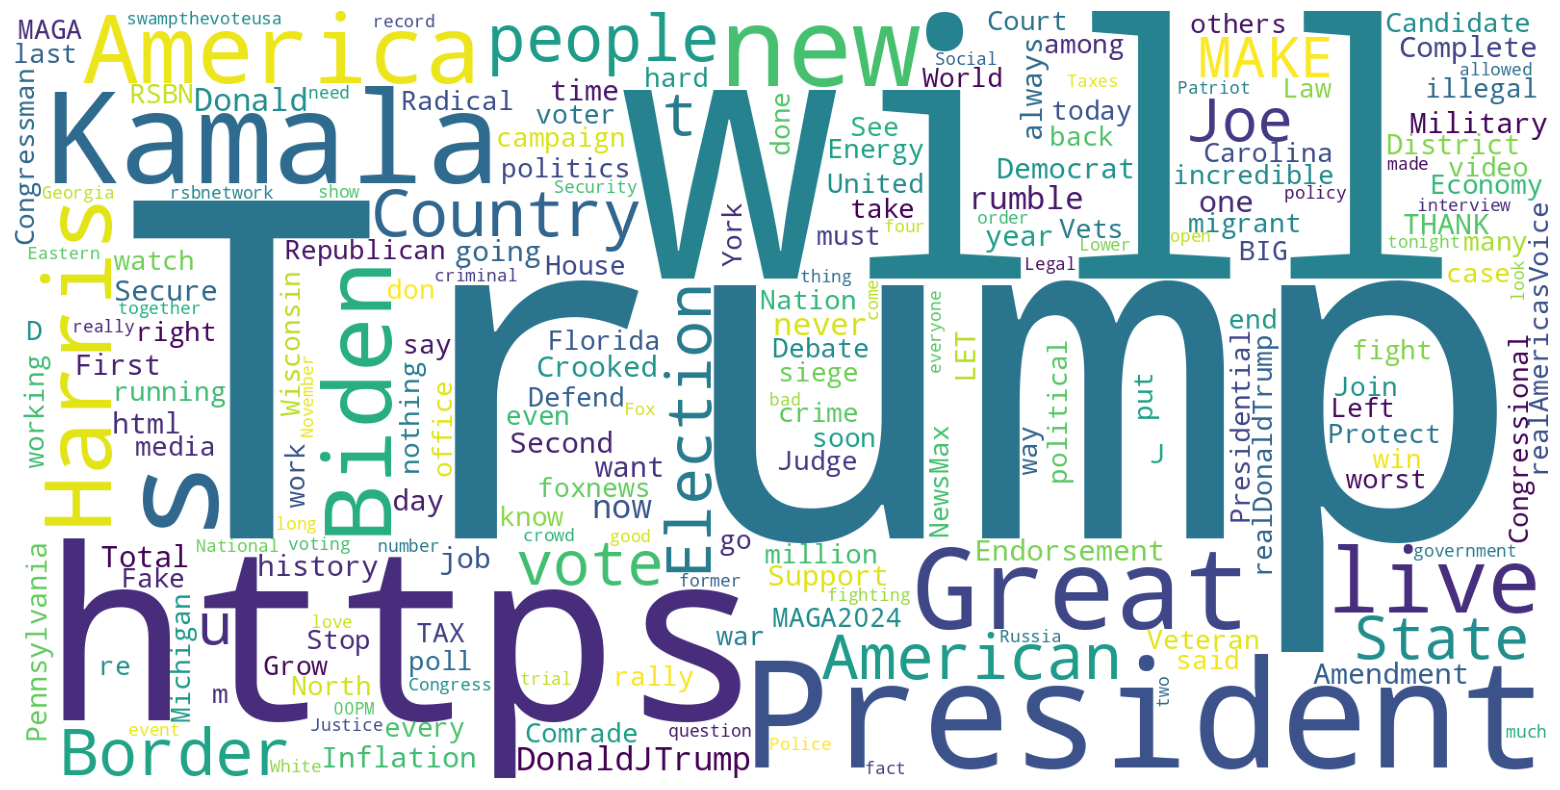

In [216]:
create_cloud_graph(df['status_text'])

Приведите столбец `post_date` к типу `datetime`, чтобы работать с датами.

In [217]:
df['post_date'] = pd.to_datetime(df['post_date'])

Преобразуйте метрики вовлечённости (`likes`, `replies`, `shares`) в численный формат:
   - Обработайте значения вида "5,01k", "1,41k" в 5010 и 1410 соответственно.
   - Пропущенные значения замените на 0.
   - Результатом должны быть числа, отражающие реальное количество лайков, ответов и репостов.

In [246]:
def convert_interaction(value):
    if pd.isna(value):
        return 0
    
    k_flag = False
    if 'k' in value:
        value = value[:-1]
        k_flag = True
    
    value = value.replace(',', '.')
    value = float(value)
    if k_flag:
        value *= 1000
    
    return int(round(value))

df['likes_count'] = df['likes'].apply(convert_interaction)
df['replies_count'] = df['replies'].apply(convert_interaction)
df['shares_count'] = df['shares'].apply(convert_interaction)

Создайте два бинарных признака:
   - `has_video` — 1, если пост содержит видео, иначе 0
   - `has_image` — 1, если пост содержит изображение, иначе 0

In [247]:
df['has_video'] = df['video_urls'].notna().astype(int)
df['has_image'] = df['image_urls'].notna().astype(int)

Выведете на экран информацию о пропусках в данных. Если пропуски присутствуют заполните их строкой 'Unknown'.

In [220]:
print(df.isna().sum())
df = df.fillna('Unknown')

account_name         0
account_handle       0
verified_badge       0
post_date            0
profile_link         1
avatar_url           0
post_url           761
status_text          0
video_urls        4165
replies              0
shares               0
likes                0
image_urls        3867
likes_count          0
replies_count        0
shares_count         0
has_video            0
has_image            0
dtype: int64


## Задание 2 - Построение графиков (2 балла)

Чтобы посмотреть в каких диапозонах лежат наши данные, давайте посмотрим на них внимательнее

Постройте график распределения по лайкам, репостам, комментариям в виде столбчатой диаграммы. Визуализируйте распределение метрик вовлечённости с помощью strip-плота, чтобы увидеть разброс значений.


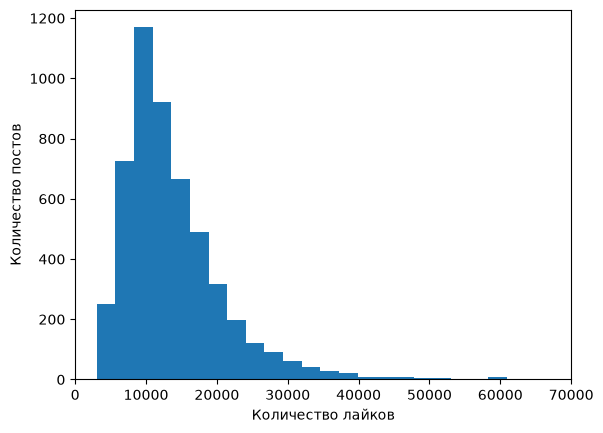

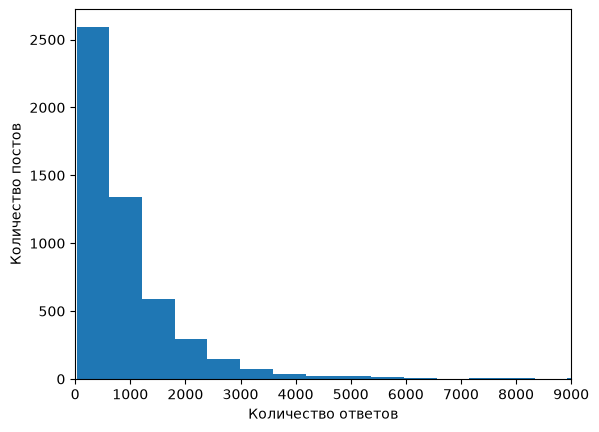

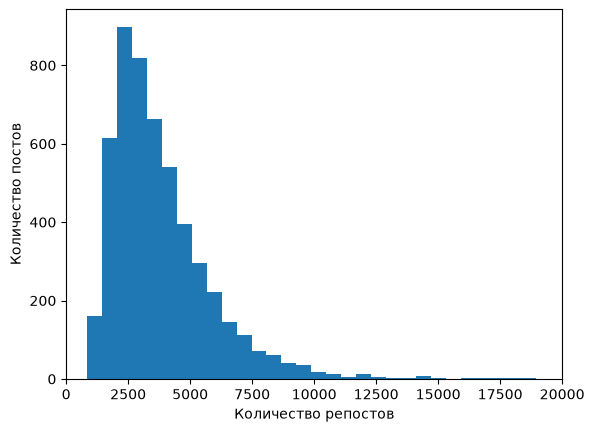

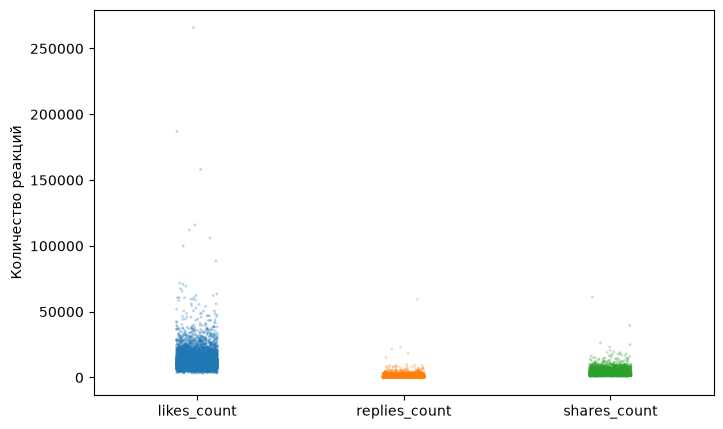

In [221]:
plt.hist(df['likes_count'], bins=100)
plt.xlim(0, 70000)
plt.xlabel('Количество лайков')
plt.ylabel('Количество постов')
plt.show()

plt.hist(df['replies_count'], bins=100)
plt.xlim(0, 9000)
plt.xlabel('Количество ответов')
plt.ylabel('Количество постов')
plt.show()

plt.hist(df['shares_count'], bins=100)
plt.xlim(0, 20000)
plt.xlabel('Количество репостов')
plt.ylabel('Количество постов')
plt.show()

plt.figure(figsize=(8, 5))
sns.stripplot(
    data=df[['likes_count', 'replies_count', 'shares_count']],
    jitter=True, size=2, alpha=0.3
)
plt.ylabel('Количество реакций')
plt.show()

Постройте круговую диаграмму, отражающую распределение постов по типу контента: с видео, с изображениями и только текст.

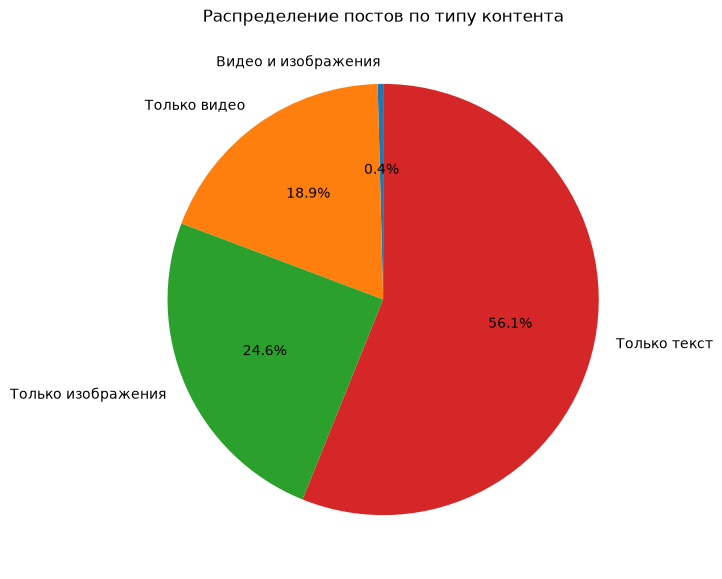

In [222]:
cnt_vid_img = len(df[
    (df['has_image'] == 1) & (df['has_video'] == 1)
])

cnt_vid = len(df[
    (df['has_image'] == 0) & (df['has_video'] == 1)
])

cnt_img = len(df[
    (df['has_image'] == 1) & (df['has_video'] == 0)
])

cnt_txt = len(df[
    (df['has_image'] == 0) & (df['has_video'] == 0)
])

counts = [cnt_vid_img, cnt_vid, cnt_img, cnt_txt]
labels = ['Видео и изображения', 'Только видео',
          'Только изображения', 'Только текст']

plt.figure(figsize=(7, 7))
plt.pie(counts, labels=labels, autopct='%.1f%%', startangle=90)
plt.title('Распределение постов по типу контента')
plt.show()


Соберите статистику по данным:
   - общее количество постов
   - среднее по лайкам, репостам и комментариям

   
Придумайте и выведите ещё 3 статистики, которые вы считаете важными для понимания данных

In [223]:
cnt_posts = cnt_img + cnt_vid + cnt_vid_img + cnt_txt

def count_above_3mean(values):
    return (values > 3 * values.mean()).sum()

print('Количество постов:', cnt_posts)

df[['likes_count', 'replies_count', 'shares_count']].agg(
    ['mean', 'median', 'std', count_above_3mean]
)


Количество постов: 5159


,likes_count,replies_count,shares_count
mean,14084.698585,941.685016,3855.124055
median,12100.000000,614.000000,3320.000000
std,9303.055053,1380.158605,2359.140741
count_above_3mean,57.000000,239.000000,54.000000


Количество постов, где метрика в 3 раза больше среднего, примерно отражает количество потенциальных выбросов (или постов которые стали очень популярными/ценными)

Сделайте выводы:
   - Какой тип контента вызывает больше реакций?
   - Как выглядит распределение проявлений активности?
   - Есть ли выбросы в данных?

In [224]:
metrics = ['likes_count', 'replies_count', 'shares_count']

mean_vid_img = df[
    (df['has_image'] == 1) & (df['has_video'] == 1)
][metrics].mean()

mean_vid = df[
    (df['has_image'] == 0) & (df['has_video'] == 1)
][metrics].mean()

mean_img = df[
    (df['has_image'] == 1) & (df['has_video'] == 0)
][metrics].mean()

mean_txt = df[
    (df['has_image'] == 0) & (df['has_video'] == 0)
][metrics].mean()

stats = pd.DataFrame({
    'Видео и изображения': mean_vid_img,
    'Только видео': mean_vid,
    'Только изображения': mean_img,
    'Только текст': mean_txt
})

stats.round(1)


,Видео и изображения,Только видео,Только изображения,Только текст
likes_count,17542.9,14481.6,12946.2,14426.2
replies_count,1344.8,944.3,738.7,1027.0
shares_count,5155.2,4205.8,3516.9,3876.3


In [225]:
df.loc[df['likes_count'].idxmax()]

account_name                                        Donald J. Trump
account_handle                                      realDonaldTrump
verified_badge                                                 True
post_date                                       2024-07-13 20:42:00
profile_link               https://truthsocial.com/@realDonaldTrump
avatar_url        https://static-assets-1.truthsocial.com/tmtg:p...
post_url          https://truthsocial.com/@realDonaldTrump/posts...
status_text       I want to thank The United States Secret Servi...
video_urls                                                  Unknown
replies                                                       59,4k
shares                                                        61,2k
likes                                                          266k
image_urls                                                  Unknown
likes_count                                                  266000
replies_count                                   

**Ответ:** 
По таблице средних метрик видно что посты, в которых есть и видео и изображение, обгоняют другие типы постов по количеству реакций. Но тут надо учитывать, что постов где есть видео и изображение всего 0,4% от всей выборки, возможно к таким показателям приводит какое-то другое особое свойство таких постов. Также, например, пост с наибольшим количеством реакций, не имеет ни видео ни фото

По гистограммам можно видеть что по каждой метрике есть правосторонняя асимметрия. Большинство постов получает умеренное количество реакций, а редкие высокие значения формируют правый хвост


В выборке есть выбросы, посты которые сильно превышают средние показатели. Также есть пост, где число лайков более 250к, выше 50к ответов и более 50к репостов. Он имеет максимальные показатели одновременно по всем трем метрикам и его можно считать выбросом



## Задание 3 Токенизация (5 баллов)

- **Токен** — это отдельная единица текста, например, слово, слог или символ
- **Токенизация** — процесс разбиения текста на токены.  
- **Токенизатор** — инструмент, который выполняет это разбиение.  

Постройте частотный словарь токенов на основе столбца `status_text` и посчитайте количество встреч каждого токена с использованием самой простой токенизации - деления текстов по пробельным символам и приведение токенов в нижний регистр

In [226]:
from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer(
    lowercase=True, tokenizer=str.split, token_pattern=None
)

X = vectorizer.fit_transform(df['status_text'])


Какой размер словаря получился?

In [227]:
print('Размер словаря:', X.shape[1])

Размер словаря: 17306


Выведите 10 самых популярных токенов с количеством встреч каждого из них. Объясните, почему именно эти токены в топе

In [228]:
token_stats = pd.DataFrame({
    'Токен': vectorizer.get_feature_names_out(),
    'Частота': np.asarray(X.sum(axis=0)).ravel()
})

token_stats.sort_values('Частота', ascending=False).head(10)

,Токен,Частота
14785,the,5992
1618,and,4428
15013,to,3361
11038,of,2796
1033,a,2541
8389,in,2262
8764,is,2143
11261,our,1644
16234,will,1551
6104,for,1439


**Ответ:**
Самые частовстречающиеся слова почти не несут смысла по отдельности, здесь встречаются предлоги, союзы и прочее. Они в топе потому что часто содержатся в предложении независимо от темы, условно для союза существует n различных пар слов между которыми он стоит. Тогда по частотам союз будет посчитан n раз, а каждое слово из тех пар по одному разу


Стоп-слова — это распространённые слова, которые не несут большой смысловой нагрузки в контексте анализа текста. Обычно это предлоги, союзы, артикли, вспомогательные глаголы и т.п., например:

- ['the', 'is', 'and', 'in', 'of', 'to', 'a', 'an', 'on', 'with']

Удалите стоп-слова из словаря, используя stopwords из библиотеки nltk и выведите новый топ-10 токенов (и количество встреч) по популярности. Что можно сказать  о нем?

In [229]:
import nltk
from nltk.corpus import stopwords

stop = set(stopwords.words('english'))

token_stats_clean = token_stats[
    ~token_stats['Токен'].isin(stop)
]

token_stats_clean.sort_values('Частота', ascending=False).head(10)


,Токен,Частота
12067,president,707
6623,great,694
15254,trump,669
9098,kamala,641
396,-,443
1539,america,442
11583,people,411
9893,make,367
8964,joe,356
10751,never,334


**Ответ:**  
Теперь в топ 10 действительно слова которые несут смысл (кроме знака -). По ним можно видеть, что Трамп в основном пишет про себя, Америку, и других политических представителей страны. Это похоже на реальность и хорошо отражает сферу его интересов 

Также выведите 20 самых непопулярных слов (если самых непопулярных слов больше выведите любые 20 из них) Почему эти токены непопулярны, требуется ли как-то дополнительно работать с ними?

In [230]:
token_stats_clean.sort_values('Частота', ascending=False).tail(20)

,Токен,Частота
4343,"defense.""",1
4344,defenses,1
10340,misconduct.,1
4345,defiant,1
4355,deflating,1
10323,minute:,1
4354,"definitively,",1
10326,minutes!),1
4351,defines,1
4350,defined.,1


**Ответ:** 
Видно что большинство слов могли бы встречаться чаще, если бы не содержали дополнительных пунктуационных символов. Так как парсинг идет по пробелу, то все остальные знаки он приписывает либо к левому слову, либо к правому. Это делает токены уникальными, хотя на деле слово одно и то же


Теперь воспользуемся токенайзером получше - TweetTokenizer из библиотеки nltk. Примените его и посмотрите на топ-10 популярных слов. Чем он отличается от топа, который получался раньше? Почему?

In [231]:
from nltk.tokenize import TweetTokenizer


tokenizer = TweetTokenizer()
vectorizer = CountVectorizer(
    tokenizer=tokenizer.tokenize,
    token_pattern=None,
    lowercase=True
)

X_tweet = vectorizer.fit_transform(df['status_text'])

stats = pd.DataFrame({
    'Токен': vectorizer.get_feature_names_out(),
    'Частота': np.asarray(X_tweet.sum(axis=0)).ravel()
})

stats.sort_values('Частота', ascending=False).head(10)



,Токен,Частота
128,",",10290
9209,the,6121
136,.,5817
906,and,4596
0,!,3872
9327,to,3402
6837,of,2807
576,a,2642
5321,in,2312
5559,is,2184


**Ответ:** 
Тут как и раньше есть слова-связки, но теперь добавились пунктуационные знаки. В прошлый раз из-за парсинга по пробелу эти знаки приклеивались к рядом стоящим словам, сейчас они отделились в отдельный символ, значит после очистки от них, уйдет проблема которая была видна в частотах с конца ранее 


Удалите из словаря стоп-слова и пунктуацию посмотрите на новый топ-10 слов с количеством встреч, есть ли теперь в нем что-то не похожее на слова?

In [232]:
from string import punctuation


is_punctuation = stats['Токен'].map(
    lambda token: all(char in punctuation for char in token)
)

stats_clean = stats[
    ~stats['Токен'].isin(stop) & ~is_punctuation
]

stats_clean.sort_values('Частота', ascending=False).head(10)

,Токен,Частота
10220,’,1836
9465,trump,1112
10221,“,985
10222,”,969
7432,president,887
10218,—,850
5715,kamala,823
3944,great,713
875,america,618
10224,…,522


**Ответ:** Осмысленных слов стало больше, но все равно остаются мелкие токены, которые относятся к форматированию текста, а не к его сути

Удалите из словаря токены из одного символа, с позицией в таблице Unicode 128 и более (`ord(x) >= 128`)

Выведите топ-10 самых популярных и топ-20 непопулярных слов. Чем полученные топы отличаются от итоговых топов, полученных при использовании токенизации по пробелам? Что теперь лучше, а что хуже?

In [233]:
is_unicode_symbol = stats_clean['Токен'].map(
    lambda token: len(token) == 1 and ord(token) >= 128
)

stats_unicode_clean = stats_clean[~is_unicode_symbol]


display(
    stats_unicode_clean.sort_values('Частота', ascending=False).head(10)
)

display(
    stats_unicode_clean.sort_values('Частота').head(20)
)

,Токен,Частота
9465,trump,1112
7432,president,887
5715,kamala,823
3944,great,713
875,america,618
2280,country,509
4086,harris,503
1344,biden,493
7139,people,489
1456,border,430


,Токен,Частота
3,#2024election,1
5099,https://www.thedupreereport.com/2024/10/cbs-co...,1
5098,https://www.the-express.com/news/politics/1476...,1
5097,https://www.the-express.com/news/politics/1392...,1
5096,https://www.telegraph.co.uk/us/politics/2024/1...,1
5095,https://www.telegraph.co.uk/us/comment/2024/05...,1
5093,https://www.sos.state.mn.us/elections-voting/o...,1
5092,https://www.simonandschuster.com/books/amateur...,1
5091,https://www.si.com/college/alabama/football/tr...,1
5090,https://www.rsbnetwork.com/video/live-trump-ho...,1


**Ответ:** Лучше тем что в топ 10 совсем не осталось пунктуации и прочего. Оставшаяся проблема в том что в нижнем топ 20 лежит мусор, это ссылки на сайты, каждая из которых осталась целиком уникальным токеном

Выведите топ-10 популярных хештегов с количеством встреч. Что можно сказать о них?

In [234]:
hashtags = stats_unicode_clean[
    stats_unicode_clean['Токен'].str.startswith('#')
]

hashtags.sort_values('Частота', ascending=False).head(10)

,Токен,Частота
86,#trump2024,24
82,#toobigtorig,20
46,#maga,18
75,#swampthevote,10
63,#phpnews,8
97,#truth,7
90,#trumpforce47,5
9,#americafirst,5
58,#notaxontips,5
49,#maga4thefelon,5


**Ответ:** Самый популярный из них это его предвыборный хештег, а MAGA сейчас является лозунгом республиканцев, к коим и принадлежит Дональд Трамп. В общем можно сказать что его посты тесно связаны с политикой, а его хештеги призваны увеличивать внимание к его персоне и его идеям 

То же самое удалите ссылки https, https на сайты и посмотрите, как изменился размер словаря. Будет ли информация о ссылке на конкретную страницу полезна в текстах постов?

In [235]:
is_url = stats_unicode_clean['Токен'].str.startswith(
    ('http://', 'https://')
)

stats_no_links = stats_unicode_clean[~is_url]

print('Размер до удаления ссылок:', len(stats_unicode_clean))
print('Размер после удаления ссылок:', len(stats_no_links))
print('Удалено токенов:', is_url.sum())

Размер до удаления ссылок: 10068
Размер после удаления ссылок: 9200
Удалено токенов: 868


**Ответ:** Полные ссылки на конкретные страницы часто уникальны и увеличивают размер словаря, мало помогая анализировать общую тематику текстов. При этом домен сайта или сам факт наличия ссылки могут быть полезными признаками

Используем опыт предыдущих экспериментов и напишем собственный токенайзер, улучшив TweetTokenizer. Функция tokenize должна:



*   Привести текст в нижний регистр
*   Применить TweetTokenizer для изначального выделения токенов
*   Удалить стоп-слова, пунктуацию, ссылки, токены из одного символа, с позицией в таблице Unicode 128 и более



In [236]:
tweet_tokenizer = TweetTokenizer()
stop = set(stopwords.words('english'))

def custom_tokenizer(text):
    tokens = tweet_tokenizer.tokenize(text.lower())

    return [
        token for token in tokens
        if token not in stop
        and not token.startswith(('http://', 'https://'))
        and not all(char in punctuation for char in token)
        and not (len(token) == 1 and ord(token) >= 128)
    ]


In [237]:
custom_tokenizer('This is sample text!!!! @Sample_text I, \x92\x92 https://t.co/sample  #sampletext')

['sample', 'text', '@sample_text', '#sampletext']

## Задание 4 Стемминг и Лемматизация (2 балла)

- Стемминг — это процесс приведения слов к их основе, то есть корню, который не обязательно является реальным словом в языке. Например, слово "running" превращается в "runn" или "run" в зависимости от алгоритма.


- Лемматизация — это более сложный процесс, при котором слово приводится к своей лемме (словарной форме), с учётом его грамматической роли и части речи. Например, "running" → "run", "better" → "good.

Модифицируйте написанный токенайзер, добавив в него стемминг и лемматизацию из библиотеки nltk - PorterStemmer, WordNetLemmatizer


Как изменился размер словаря в случае лемантизации и стемминга?

In [238]:
from nltk import PorterStemmer, WordNetLemmatizer

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

def custom_stem_tokenizer(text):
    return [
        stemmer.stem(token)
        for token in custom_tokenizer(text)
    ]

In [239]:
custom_stem_tokenizer('This is sample text!!!! @Sample_text I, \x92\x92 https://t.co/sample  #sampletext adding more words to check stemming')

['sampl', 'text', '@sample_text', '#sampletext', 'ad', 'word', 'check', 'stem']

In [240]:
cv = CountVectorizer(
    tokenizer=custom_stem_tokenizer,
    token_pattern=None,
    lowercase=False
)

cv.fit(df['status_text'])

print('Размер словаря после стемминга:', len(cv.vocabulary_))

Размер словаря после стемминга: 6856


**Ответ** 
В задании 3 наш итоговый словарь имел размер 9200 токенов, в случае тех же действий + стемминг мы получили 6856. Размер словаря изменился на 2400 от общего количества, примерно 25%

In [241]:
def custom_lem_tokenizer(text):
    return [
        lemmatizer.lemmatize(token)
        for token in custom_tokenizer(text)
    ]


In [242]:
custom_lem_tokenizer('This is sample text!!!! @Sample_text I, \x92\x92 https://t.co/sample  #sampletext adding more words to check stemming')

['sample',
 'text',
 '@sample_text',
 '#sampletext',
 'adding',
 'word',
 'check',
 'stemming']

In [243]:
cv = CountVectorizer(
    tokenizer=custom_lem_tokenizer,
    token_pattern=None,
    lowercase=False
)

cv.fit(df['status_text'])

print('Размер словаря после лемматизации:', len(cv.vocabulary_))

Размер словаря после лемматизации: 8428


**Ответ** После лемматизации в словаре осталось 8428 токенов, около 800 токенов оказались формами другого. Сокращение объема примерно 10%

Теперь разделите данные на обучающие и тестовые в соотношении 7 : 3 и random_state=0

In [244]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(
    df,
    test_size=0.3,
    random_state=0
)

print('Обучающая выборка:', len(train))
print('Тестовая выборка:', len(test))

Обучающая выборка: 3611
Тестовая выборка: 1548


Итак, у нас получился очищенный корпус слов, на котором уже можно запускать и обучать модели.

Поздравляю! Вы большие молодцы и прошли первый этап практики) Приступайте к следующему заданию!